## Mini-Project: Customers Like You
### This file is for ML Engineer
ML Eng Task ML1 ~ ML7 <br>

### ML1
To do : Choose PCA or Truncated SVD and write a short justification.

For our project, we decided to choose Truncated SVD after considering both methods. Truncated SVD can directly handle sparse matrices without centering the data. In contrast, PCA requires centering the data by subtracting the mean from each feature. This process may turn zero values into nonzero values, causing the matrix to lose its sparse structure. Since our customer-product matrix contains many zero values, we think Truncated SVD is more suitable for our project. We will also compare it with PCA to evaluate their performance.


In [40]:
import pandas as pd
import scipy.sparse as sp

## load data
A = sp.load_npz("A_train_log.npz")
products = pd.read_csv("products.csv", dtype={"StockCode": "string"})
customers = pd.read_csv("customers.csv")

## Check matrix properties
print(f"Matrix format: {A.getformat()}")
print(f"Matrix data type: {A.dtype}")

## Check shape consistency
assert A.shape == (len(customers), len(products))
print(f"Shape of interaction matrix: {A.shape}")
print(f"Number of customers: {len(customers)}")
print(f"Number of products: {len(products)}")

## Display sparsity information to chose the method between SVD/PCA
print(f"number of non-zero elements: {A.nnz}")
print(f"Sparsity: {(1 - A.nnz / (A.shape[0] * A.shape[1])) * 100:.2f}%")

Matrix format: csr
Matrix data type: float64
Shape of interaction matrix: (5463, 3684)
Number of customers: 5463
Number of products: 3684
number of non-zero elements: 411374
Sparsity: 97.96%


Based on the dataset provided by our data engineer, we found that our customer-product matrix is highly sparse, with approximately 98% zero values. This supports our decision to use Truncated SVD as the main method for our project.

### ML2
To do : Fit on the training matrix for k in 10, 20, 50, 100, 200. Plot reconstruction error (SVD) against k

For this task, we are going to use Truncated SVD to decompose our customer-product matrix A into three matrices:

$$
A \approx U_k \Sigma_k V_k^T
$$

In this project:

- **A (5463 × 3684):** Our original customer-product matrix. Each row represents a customer, and each column represents a product. The values are log(1 + total purchased quantity).

- **$U_k$ (5463 × k):** Represents customers in k hidden purchasing patterns. Each row shows how a customer is related to these patterns.

- **$\Sigma_k$ (k × k):** A diagonal matrix containing the singular values. These values are sorted from largest to smallest and indicate how much each component contributes to reconstructing the original matrix.

- **$V_k^T$ (k × 3684):** Represents the relationship between the k hidden purchasing patterns and the products. Each row is a component, and each column corresponds to a product.

The main idea of Truncated SVD is to reduce the original 3,684-dimensional product space into a smaller number of hidden components. Each component is a combination of the original product features, rather than a selection of individual products.

For example, when k = 50, each customer can be represented by 50 new features while still keeping information from all 3,684 products.

However, reducing the number of components also means losing some information. Therefore, we will test different values of k and calculate the relative reconstruction error to measure how well the reduced matrix can represent the original data.

We will then compare the reconstruction error for different k values and choose a suitable k based on the balance between information loss and model size.

Relative error: [np.float64(0.8756774061040389), np.float64(0.8453905053535777), np.float64(0.7889807754658915), np.float64(0.727211073834438), np.float64(0.6391373183448065)]


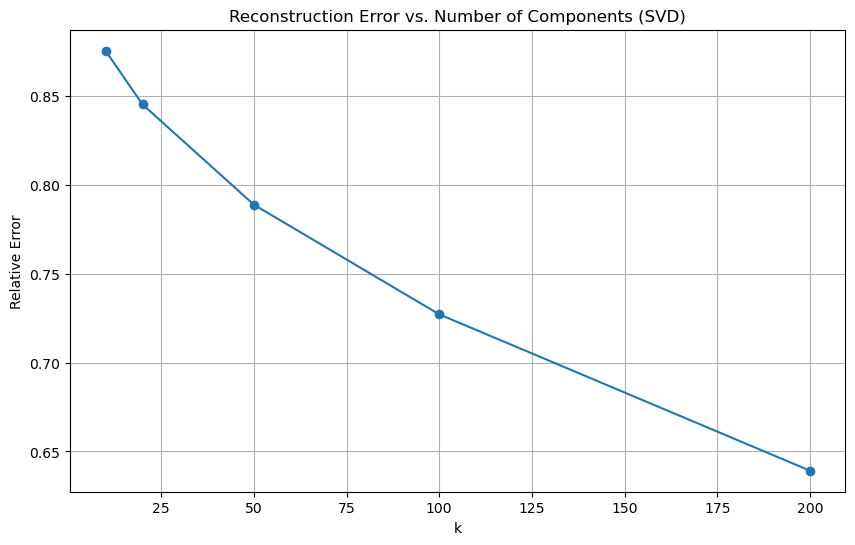

In [41]:
from sklearn.decomposition import TruncatedSVD

import numpy as np
import matplotlib.pyplot as plt

k = [10, 20, 50, 100, 200]
relative_error_list = []
total_energy = A.multiply(A).sum()

## train the svd model
for k_val in k:
    svd = TruncatedSVD(n_components = k_val, random_state = 42)
    svd.fit(A)

    ## Calculate relative_error
    singular_values = svd.singular_values_
    captured_energy = np.sum(singular_values ** 2)

    if total_energy != 0:
        relative_error = np.sqrt(total_energy - captured_energy) / np.sqrt(total_energy)
    else:
        relative_error = 0

    relative_error_list.append(relative_error)

print(f"Relative error: {relative_error_list}")

## Plot reconstruction error (SVD) against k
plt.figure(figsize=(10, 6))
plt.plot(k, relative_error_list, marker='o')
plt.xlabel('k')
plt.ylabel('Relative Error')
plt.title('Reconstruction Error vs. Number of Components (SVD)')
plt.grid(True)
plt.show()

### ML2: Results and Decision

We tested five values of k (10, 20, 50, 100, and 200) using Truncated SVD and compared their relative reconstruction errors.

As k increases, the reconstruction error decreases from 0.88 at k = 10 to 0.64 at k = 200. This means that keeping more components helps the model preserve more information from the original customer-product matrix.

We decided to choose **k = 100**. The reconstruction error at k = 50 is still relatively high (0.79), while increasing k to 100 reduces the error to 0.73. Although k = 200 gives a lower error (0.64), it requires twice as many components as k = 100, and the average improvement per additional component is smaller.

Therefore, we think k = 100 provides a reasonable balance between reconstruction error and model complexity. We will use k = 100 for our recommendation model in ML3.

### ML3
To do : Recommend: for each product, find the 10 most similar products by cosine similarity of their factor vectors. For a customer, score products by similarity to what they bought

Step 1: Get Product Vectors from Truncated SVD

Use the selected k = 100 to fit the Truncated SVD model on the training matrix. Extract the product vectors from the SVD components. Each product will be represented by 100 hidden features.

Step 2: Find Similar Products Using Cosine Similarity

Calculate the cosine similarity between product vectors and find the 10 most similar products for each product. Exclude the product itself from its recommendation list.

Step 3: Generate Recommendations for Each Customer

Use each customer's purchase history to calculate recommendation scores for other products. Exclude products the customer has already purchased and select the top 10 products with the highest scores.

Save the final recommendations as `recs_svd.npy` for evaluation.

In [42]:
from sklearn.preprocessing import normalize
import csv

## Based on the results above, we choose k = 100.
svd = TruncatedSVD(n_components = 100, random_state = 42)
svd.fit(A)

product_vectors = svd.components_.T
print(product_vectors.shape)

product_normalize = normalize(product_vectors, axis = 1, norm = 'l2') 

similarity_matrix = product_normalize @ product_normalize.T
print(similarity_matrix.shape)

(3684, 100)
(3684, 3684)


In [43]:
product_similarity = similarity_matrix.copy()
np.fill_diagonal(product_similarity, -np.inf)

top_10_recommendations = np.argsort(product_similarity)[:, -10:][:, ::-1]
print(top_10_recommendations.shape)

products = pd.read_csv(
    "products.csv",
    dtype={"StockCode": "string"}
)

## Show the top 10 similar products for product 0
product_idx = 0

print("Original Product:", products.iloc[product_idx]["Description"])
print("\nTop 10 Similar Products:")

for idx in top_10_recommendations[product_idx]:
    product_name = products.iloc[idx]["Description"]
    similarity = similarity_matrix[product_idx, idx]
    print(f"{product_name}: {similarity:.4f}")

(3684, 10)
Original Product: INFLATABLE POLITICAL GLOBE

Top 10 Similar Products:
VINTAGE RED MUG: 0.4601
SMALL CHUNKY GLASS ROMAN  BOWL: 0.4378
KIDS RAIN MAC BLUE: 0.4318
VINTAGE RED TEATIME MUG: 0.4130
KIDS RAIN MAC PINK: 0.4089
BLUE SAVANNAH PICNIC HAMPER FOR 4: 0.4068
PINK HAWAIIAN PICNIC HAMPER FOR 2: 0.4066
WRAP BLUE RUSSIAN FOLKART: 0.3982
LARGE CHUNKY GLASS ROMAN BOWL: 0.3977
POLKADOT RAIN HAT: 0.3923


In [44]:
## calculate the product score for every customer
customer_scores = A @ similarity_matrix
print(customer_scores.shape)
print(np.isnan(customer_scores).sum())

## we want to remove the product already be purchased
purchased = A.nonzero()
customer_scores[purchased] = -np.inf

## top_10 product_insices
top_10_indices = np.argsort(customer_scores)[:, -10:][:, ::-1]
print(top_10_indices.shape)
print(top_10_indices.dtype)
print(top_10_indices[0])

## built recs_svd.npy for top_10 product_indices
np.save('recs_svd.npy', top_10_indices)
print("Top 10 recommended products saved to recs_svd.npy")

(5463, 3684)
0
(5463, 10)
int64
[2685 2688 2693 1467 2684 2695 2269 2692 2694 2270]
Top 10 recommended products saved to recs_svd.npy


In [45]:
## Check rec_svd.npy
recs = np.load("recs_svd.npy")
print(recs.shape)
!python validate_recommendations.py recs_svd.npy

(5463, 10)
PASS: shape, dtype, range, uniqueness, and exclusion of training purchases


### ML3: Results

We used Truncated SVD with k = 100 to represent each product with 100 features. We normalized the product vectors and calculated cosine similarity to find the 10 most similar products for each product.

For example, the most similar products to "INFLATABLE POLITICAL GLOBE" include mugs, bowls, and raincoats. These products are not necessarily similar in their functions because our model learns from customer purchase patterns rather than product descriptions. The highest cosine similarity is 0.4601, which suggests that the similarity is not very strong.

For each customer, we calculated recommendation scores based on their purchase history and product similarity. We excluded products that the customer had already purchased and selected the top 10 products with the highest scores.

Finally, we saved the recommendations as `recs_svd.npy`. The file contains recommendations for 5,463 customers, with 10 products for each customer. It passed the validation checks for shape, data type, product indices, uniqueness, and exclusion of previously purchased products.

The recommendation performance is evaluated using Hit Rate@10 in ML4.


### ML4: Efficiency and Evaluation
To do: Measure the efficiency and recommendation performance of our Truncated SVD model.

Step 1: Measure SVD Training Time

Measure how long it takes to fit the Truncated SVD model with k = 100.

Step 2: Measure Recommendation Time

Measure the time needed to generate the top 10 product recommendations for all 5,463 customers.

Step 3: Measure Factor Storage Size

Calculate the storage size of the SVD factors used by the recommendation model.

Step 4: Evaluate Hit Rate@10

Use the held-out test data evaluation results from our Data Engineer to measure recommendation performance.


In [46]:
from threadpoolctl import threadpool_limits
import time

## step 1: Measure SVD Training Time
with threadpool_limits(limits=1):
    svd = TruncatedSVD(n_components=100, random_state=42)

    start = time.perf_counter()
    svd.fit(A)
    end = time.perf_counter()

training_time = end - start

print(f"SVD Training Time: {training_time:.4f} seconds")

SVD Training Time: 0.3037 seconds


In [47]:
## Step 2: Measure Recommendation Time

with threadpool_limits(limits=1):
    start = time.perf_counter()

    customer_scores = A @ similarity_matrix

    purchased = A.nonzero()
    customer_scores[purchased] = -np.inf

    top_10_indices = np.argsort(customer_scores)[:, -10:][:, ::-1]

    end = time.perf_counter()

recommendation_time = end - start

print(f"Recommendation Time: {recommendation_time:.4f} seconds")
print(f"Recommendations Shape: {top_10_indices.shape}")

Recommendation Time: 0.9858 seconds
Recommendations Shape: (5463, 10)


In [48]:
print(svd.components_.shape)
print(svd.components_.nbytes)

customer_factors = svd.transform(A)

print(customer_factors.shape)
print(customer_factors.nbytes)

total_bytes = customer_factors.nbytes + svd.components_.nbytes

total_size_mib = total_bytes / (1024 ** 2)

print(f"Total Factor Size: {total_size_mib:.4f} MiB")

(100, 3684)
2947200
(5463, 100)
4370400
Total Factor Size: 6.9786 MiB


### ML4: Results

Step 1: SVD Training Time

We measured the training time of Truncated SVD with k = 100. Using one thread, the model took 0.3037 seconds to fit the training matrix.

We also found that using multiple threads made the training much slower in our environment. Therefore, we used one thread for the timing experiment.

Step 2: Recommendation Time

We measured the time needed to generate the top 10 product recommendations for all 5,463 customers.

Using one thread, the recommendation process took 0.9858 seconds. This includes calculating recommendation scores, excluding previously purchased products, and selecting the top 10 products for each customer.

The timing does not include SVD training or the calculation of the product similarity matrix.

Step 3: Factor Storage Size

We calculated the memory size of the customer and product factors from Truncated SVD with k = 100.

The product factors use 2.81 MiB, and the customer factors use 4.17 MiB. Together, they require approximately 6.98 MiB.

This measurement only includes the two factor arrays. It does not include the original training matrix, product similarity matrix, or other intermediate results.

### Recommendation Evaluation

We evaluated the recommendations using held-out customer purchases.
The evaluation included 1,906 customers with at least one eligible
test purchase. Each customer was counted as a hit if at least one
recommended product appeared in their held-out purchases.

| Method | Hit Rate@10 |
|---|---:|
| Best-seller Baseline | 17.37% |
| Truncated SVD (Log) | 23.50% |

Our SVD model achieved a Hit Rate@10 of 23.50%, compared to
17.37% for the best-seller baseline. This means SVD performed
6.14 percentage points better than simply recommending popular
products.


### ML5: PCA vs. Truncated SVD

To do: Compare PCA and Truncated SVD using the same number of components (k = 100).

Step 1: Fit PCA

Use PCA with `svd_solver="arpack"` on the training matrix.

Step 2: Compare Reconstruction Error

Compare how well PCA and Truncated SVD preserve information from the original matrix.

Step 3: Compare Efficiency

Measure training time, peak memory usage, and factor storage size.

Step 4: Compare Recommendation Performance

Generate the top 10 recommendations using PCA and save them as `recs_pca.npy`. Compare Hit Rate@10 using the evaluation results from our Data Engineer.

Step 5: Discuss the Results

Explain the differences between PCA and Truncated SVD and discuss which method is more suitable for our recommendation system.


In [58]:
import tracemalloc
from sklearn.decomposition import PCA

## Compare PCA and Truncated SVD
k = 100

## Step 1: Fit both models and measure training time and peak memory
def fit_and_measure(model, A):
    tracemalloc.start()
    start = time.perf_counter()

    with threadpool_limits(limits=1):
        model.fit(A)

    training_time = time.perf_counter() - start
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    return training_time, peak_memory / (1024 ** 2)


svd = TruncatedSVD(n_components=k, random_state=42)
pca = PCA(n_components=k, svd_solver="arpack", random_state=42)

svd_time, svd_peak_memory = fit_and_measure(svd, A)
pca_time, pca_peak_memory = fit_and_measure(pca, A)

print(f"SVD Training Time: {svd_time:.4f} seconds")
print(f"PCA Training Time: {pca_time:.4f} seconds")


## Step 2: Calculate reconstruction error without converting A to dense
def reconstruction_error(model, A, method):
    with threadpool_limits(limits=1):
        transformed = model.transform(A)

    total_energy = float(A.multiply(A).sum())

    if method == "svd":
        captured_energy = float(np.sum(transformed ** 2))
        error_squared = total_energy - captured_energy

    elif method == "pca":
        mean = model.mean_
        centered_energy = (
            total_energy
            - A.shape[0] * float(np.sum(mean ** 2))
        )
        captured_energy = float(np.sum(transformed ** 2))
        error_squared = centered_energy - captured_energy

    return np.sqrt(max(0, error_squared) / total_energy)


svd_error = reconstruction_error(svd, A, "svd")
pca_error = reconstruction_error(pca, A, "pca")

print(f"SVD Reconstruction Error: {svd_error:.4f}")
print(f"PCA Reconstruction Error: {pca_error:.4f}")


## Step 3: Measure factor storage size
def factor_size(model, A):
    with threadpool_limits(limits=1):
        customer_factors = model.transform(A)

    total_bytes = customer_factors.nbytes + model.components_.nbytes

    if hasattr(model, "mean_"):
        total_bytes += model.mean_.nbytes

    return total_bytes / (1024 ** 2)


svd_factor_size = factor_size(svd, A)
pca_factor_size = factor_size(pca, A)

print(f"SVD Factor Size: {svd_factor_size:.4f} MiB")
print(f"PCA Factor Size: {pca_factor_size:.4f} MiB")


## Step 4: Generate PCA recommendations
with threadpool_limits(limits=1):
    pca_product_vectors = pca.components_.T
    pca_product_normalize = normalize(
        pca_product_vectors, axis=1, norm="l2"
    )

    pca_similarity_matrix = (
        pca_product_normalize @ pca_product_normalize.T
    )

    pca_customer_scores = A @ pca_similarity_matrix

    purchased = A.nonzero()
    pca_customer_scores[purchased] = -np.inf

    pca_top_10 = np.argsort(
        pca_customer_scores, axis=1
    )[:, -10:][:, ::-1]

np.save("recs_pca.npy", pca_top_10)

print(f"PCA Recommendations Shape: {pca_top_10.shape}")
print("Saved recs_pca.npy")


## Step 5: Compare PCA and Truncated SVD


comparison = pd.DataFrame({
    "Measure": [
        "k used",
        "Fit time (seconds)",
        "Peak Python memory during fit (MiB)",
        "Size of stored factors (MiB)",
        "Relative reconstruction error",
        "Hit Rate@10 (%)"
    ],
    "PCA": [
        k,
        round(pca_time, 4),
        round(pca_peak_memory, 2),
        round(pca_factor_size, 2),
        round(pca_error, 4),
        22.67
    ],
    "Truncated SVD": [
        k,
        round(svd_time, 4),
        round(svd_peak_memory, 2),
        round(svd_factor_size, 2),
        round(svd_error, 4),
        23.50
    ]
})

display(comparison)


SVD Training Time: 0.3380 seconds
PCA Training Time: 0.3166 seconds
SVD Reconstruction Error: 0.7269
PCA Reconstruction Error: 0.7257
SVD Factor Size: 6.9786 MiB
PCA Factor Size: 7.0067 MiB
PCA Recommendations Shape: (5463, 10)
Saved recs_pca.npy


,Measure,PCA,Truncated SVD
0,k used,100.0000,100.0000
1,Fit time (seconds),0.3166,0.3380
2,Peak Python memory during fit (MiB),15.8900,17.0000
3,Size of stored factors (MiB),7.0100,6.9800
4,Relative reconstruction error,0.7257,0.7269
5,Hit Rate@10 (%),22.6700,23.5000


In [50]:
## show the profile of the first component
def show_component_1(model, products, top_n=10):
    weights = model.components_[0]
    indices = np.argsort(np.abs(weights))[-top_n:][::-1]

    return pd.DataFrame({
        "Product": products.iloc[indices]["Description"].values,
        "Weight": weights[indices]
    })

print("SVD Component 1")
display(show_component_1(svd, products))

print("PCA Component 1")
display(show_component_1(pca, products))

SVD Component 1


,Product,Weight
0,PACK OF 72 RETRO SPOT CAKE CASES,0.130291
1,WHITE HANGING HEART T-LIGHT HOLDER,0.121667
2,JUMBO BAG RED RETROSPOT,0.108709
3,LUNCH BAG RED RETROSPOT,0.100878
4,60 TEATIME FAIRY CAKE CASES,0.091641
5,ASSORTED COLOUR BIRD ORNAMENT,0.087475
6,PACK OF 60 PINK PAISLEY CAKE CASES,0.085220
7,LUNCH BAG SPACEBOY DESIGN,0.080984
8,SET/20 RED SPOTTY PAPER NAPKINS,0.080595
9,LUNCH BAG PINK POLKADOT,0.077796


PCA Component 1


,Product,Weight
0,PACK OF 72 RETRO SPOT CAKE CASES,0.123336
1,JUMBO BAG RED RETROSPOT,0.106432
2,LUNCH BAG RED RETROSPOT,0.103790
3,WHITE HANGING HEART T-LIGHT HOLDER,0.093619
4,60 TEATIME FAIRY CAKE CASES,0.087021
5,LUNCH BAG SPACEBOY DESIGN,0.082995
6,PACK OF 60 PINK PAISLEY CAKE CASES,0.081895
7,LUNCH BAG PINK POLKADOT,0.081207
8,LUNCH BAG CARS BLUE,0.079364
9,SET/20 RED SPOTTY PAPER NAPKINS,0.078734


In [51]:
## Check rec_pca.npy
recs = np.load("recs_pca.npy")
print(recs.shape)
!python validate_recommendations.py recs_pca.npy

(5463, 10)
PASS: shape, dtype, range, uniqueness, and exclusion of training purchases


### ML5 results

Both PCA and Truncated SVD showed similar results with k = 100. Their training times were close in our experiment, while PCA had a slightly lower reconstruction error (0.7257 vs. 0.7269).

PCA used slightly more storage than SVD (7.01 MiB vs. 6.98 MiB). For the measured Python memory, PCA used 15.89 MiB and SVD used 17.00 MiB, but these numbers may not include all memory used during training.

The first components of both models were also very similar, with 9 out of the top 10 products being the same. 

The larger absolute weights show which products contribute more to the first component. In our results, the top products have positive weights, suggesting that they contribute in the same direction to this purchasing pattern.

These products mainly included baking supplies, lunch bags, and home decorations. 

This suggests that both models captured a similar purchasing pattern. However, SVD works directly with the original purchase matrix, while PCA focuses on differences from the average purchasing behavior.

Overall, Truncated SVD seems more suitable for our sparse customer-product matrix because it was faster and had almost the same reconstruction error as PCA. 

### Recommendation Performance

| Method | Hit Rate@10 |
|---|---:|
| Truncated SVD (Log) | 23.50% |
| PCA (Log) | 22.67% |

Both methods performed better than the best-seller baseline.
SVD achieved a slightly higher hit rate than PCA, with a
difference of about 0.83 percentage points.

Together with its slightly smaller stored factors and its ability to work directly with sparse matrices, these results support our choice of Truncated SVD as the main method.


### ML6: Customer Map and Clustering

To do: Customer map: project customers on 2 components, cluster into 3 to 6 groups
(for example k-means), describe each group with its top products and countries

Step 1: Normalize Customer Data

Normalize each customer's purchase vector to reduce the effect of different purchase amounts.

Step 2: Reduce to 2 Components

Use Truncated SVD to project customers into a 2D space.

Step 3: Customer Clustering

Use KMeans to divide customers into 3 to 6 groups.

Step 4: Visualize Customer Groups

Create a scatter plot to show the customer groups in the 2D space.

Step 5: Analyze Customer Groups

Find the top products and countries in each group using `products.csv` and `customers.csv`. Give each group a name based on its purchasing patterns.

In [52]:

from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

## Step 1: Normalize customer purchase vectors
A_normalized = normalize(A, norm="l2", axis=1)

## Step 2: Project customers onto 2 components
with threadpool_limits(limits=1):
    svd_2d = TruncatedSVD(
        n_components = 2,
        random_state = 42
    )
    customer_2d = svd_2d.fit_transform(A_normalized)

print("Original matrix:", A.shape)
print("Normalized matrix:", A_normalized.shape)
print("Customer 2D coordinates:", customer_2d.shape)

Original matrix: (5463, 3684)
Normalized matrix: (5463, 3684)
Customer 2D coordinates: (5463, 2)


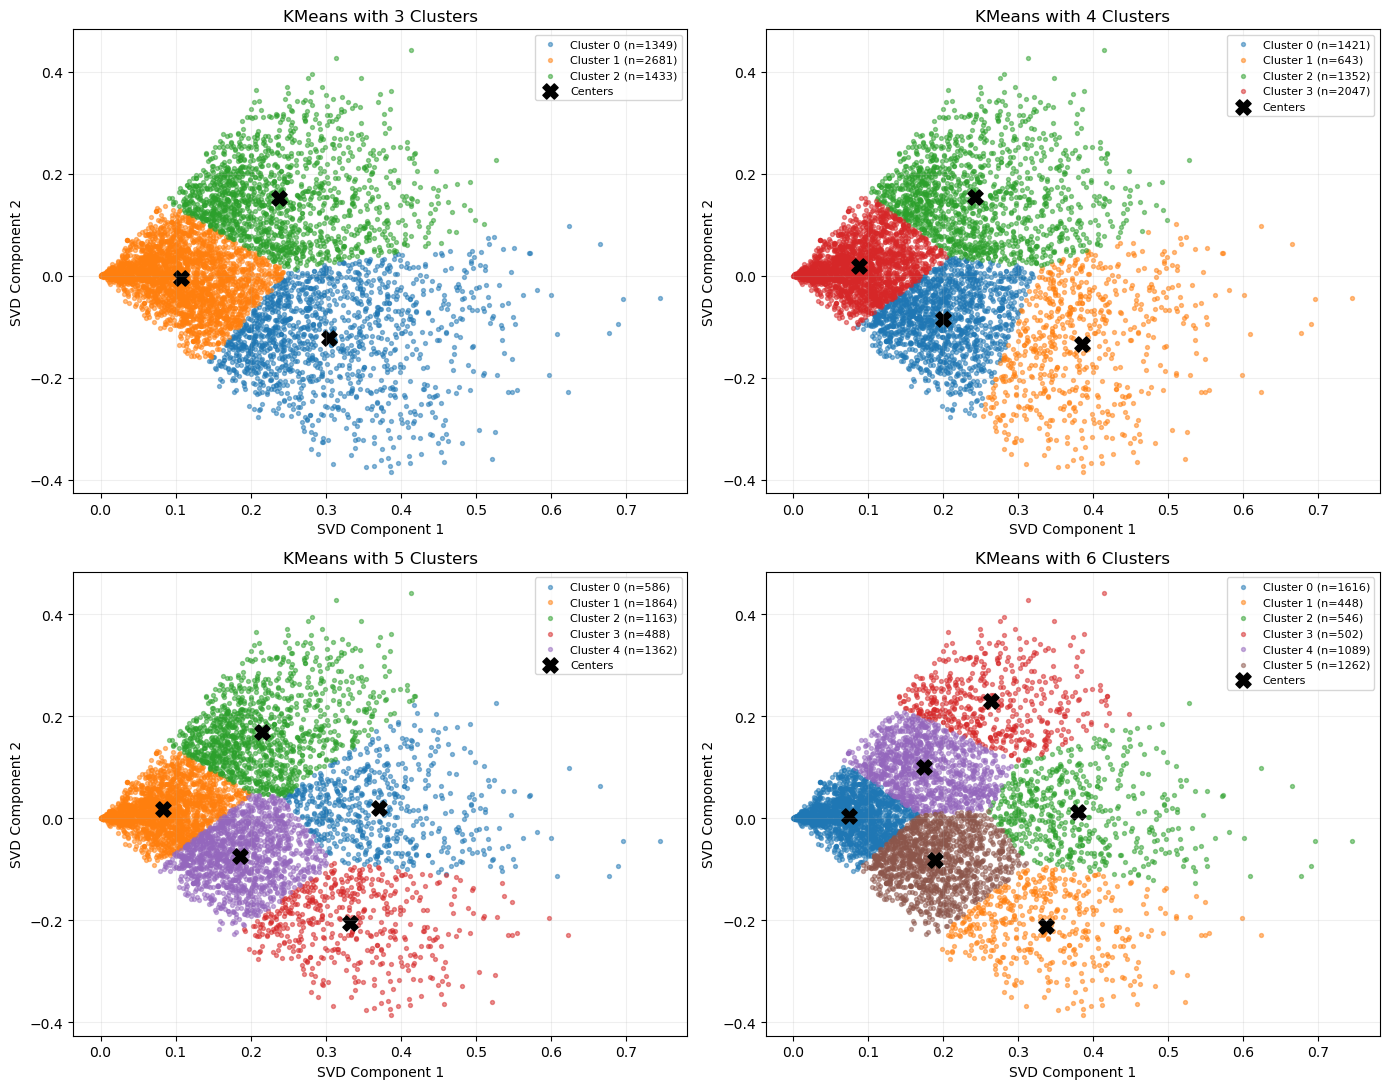

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Step 3: Compare 3 to 6 clusters
# Compare KMeans with 3, 4, 5, and 6 clusters
cluster_options = [3, 4, 5, 6]
cluster_results = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, n_clusters in zip(axes.flat, cluster_options):

    with threadpool_limits(limits=1):
        kmeans = KMeans(
            n_clusters = n_clusters,
            random_state = 42,
            n_init = 10
        )
        labels = kmeans.fit_predict(customer_2d)

    cluster_results[n_clusters] = labels

## Step 4: Visualize Customer Groups 

    # Plot each cluster separately
    for cluster_id in range(n_clusters):
        mask = labels == cluster_id

        ax.scatter(
            customer_2d[mask, 0],
            customer_2d[mask, 1],
            s = 8,
            alpha = 0.5,
            label = f"Cluster {cluster_id} (n={mask.sum()})"
        )

    # Plot cluster centers
    ax.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        marker = "X",
        s = 120,
        c = "black",
        label = "Centers"
    )

    ax.set_title(f"KMeans with {n_clusters} Clusters")
    ax.set_xlabel("SVD Component 1")
    ax.set_ylabel("SVD Component 2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### Step 3: Compare KMeans Clustering Results

We used KMeans to divide customers into 3, 4, 5, and 6 clusters and plotted the results in a 2D space.

From the four plots, 5 clusters seemed to provide a good balance. It separated customers into different regions without creating too many small groups.

We decided to use 5 clusters for the next step and examine the top products and countries in each group to see whether the clusters represent different purchasing patterns.


In [54]:
## Step 5: Analyze customer segments
n_clusters = 5
cluster_labels = cluster_results[n_clusters]

for cluster_id in range(n_clusters):
    mask = cluster_labels == cluster_id
    cluster_A = A[mask]

    ## Top products by number of customers who purchased them
    product_counts = cluster_A.getnnz(axis=0)
    top_product_indices = np.argsort(product_counts)[-5:][::-1]

    top_products = products.iloc[top_product_indices][
        ["Description"]
    ].copy()
    top_products["Customers"] = product_counts[top_product_indices]

    # Top countries
    top_countries = (
        customers.loc[mask, "Country"]
        .value_counts()
        .head(5)
    )

    print(f"\n{'=' * 45}")
    print(f"Cluster {cluster_id}: {mask.sum()} customers")

    print("\nTop 5 Products:")
    display(top_products)

    print("Top 5 Countries:")
    display(top_countries)



Cluster 0: 586 customers

Top 5 Products:


,Description,Customers
3429,WHITE HANGING HEART T-LIGHT HOLDER,425
501,PACK OF 72 RETRO SPOT CAKE CASES,319
1476,REGENCY CAKESTAND 3 TIER,297
3299,60 TEATIME FAIRY CAKE CASES,280
3408,JUMBO BAG RED RETROSPOT,267


Top 5 Countries:


Country
United Kingdom     568
Cyprus               3
Germany              3
EIRE                 3
Channel Islands      2
Name: count, dtype: int64


Cluster 1: 1864 customers

Top 5 Products:


...

Country
United Kingdom    367
Germany            34
France             27
Belgium            14
Switzerland         8
Name: count, dtype: int64


Cluster 4: 1362 customers

Top 5 Products:


,Description,Customers
501,PACK OF 72 RETRO SPOT CAKE CASES,307
1217,BAKING SET 9 PIECE RETROSPOT,297
1476,REGENCY CAKESTAND 3 TIER,250
1218,RETROSPOT TEA SET CERAMIC 11 PC,239
3408,JUMBO BAG RED RETROSPOT,228


Top 5 Countries:


Country
United Kingdom    1173
Germany             41
France              37
Spain               12
Sweden              12
Name: count, dtype: int64

### ML6 Results

We normalized the customer purchase matrix and used Truncated SVD to project 5,463 customers into a 2D space. We then compared KMeans clustering with 3, 4, 5, and 6 groups.

Based on the plots, we selected 5 clusters because they showed a reasonable separation without creating too many small groups.

We examined the top products and countries in each cluster. Some groups showed clearer purchasing patterns, such as home decorations in Cluster 2 and lunch bags in Cluster 3. Other groups had more mixed purchasing patterns.

Most customers were from the United Kingdom (93.2%), so country was less useful for distinguishing the groups. However, Cluster 3 had a relatively higher proportion of customers from other countries.

Overall, the customer map helped us identify different purchasing patterns, although some groups still shared similar popular products.


#### Customer Segments

| Cluster | Customers | Segment Name | Main Products |
|---|---:|---|---|
| 0 | 586 | Baking & Home | Cake cases, cake stands, decorations |
| 1 | 1,864 | Mixed Shoppers | Cake stands, shopping bags, party supplies |
| 2 | 1,163 | Home Decoration | Heart decorations, ornaments, chalkboards |
| 3 | 488 | Bags & Lunch | Lunch bags, jumbo bags, cake cases |
| 4 | 1,362 | Baking & Tea | Baking sets, tea sets, cake stands |


### ML7: Purchase Value Sensitivity

To do: Sensitivity: does the purchase value (count, 1/0, log) change your hit rate? 

We will use three customer-product matrices:
- **Log:** log(1 + purchase quantity)
- **Count:** Total purchase quantity
- **Binary:** 1 if a customer purchased a product, otherwise 0

We already used the log matrix for our main SVD model in ML3. In this section, we will apply the same SVD recommendation method to the count and binary matrices.

We will generate top 10 recommendations for each customer and compare their Hit Rate@10 after receiving the evaluation results from A.

In [55]:
## Load purchase value matrices

A_count = sp.load_npz("A_train_count.npz")
A_binary = sp.load_npz("A_train_binary.npz")

print("Log:", A.shape)
print("Count:", A_count.shape)
print("Binary:", A_binary.shape)

assert A.shape == A_count.shape == A_binary.shape

Log: (5463, 3684)
Count: (5463, 3684)
Binary: (5463, 3684)


In [56]:
## Generate recommendations for Count and Binary

def generate_svd_recommendations(A_input, k = 100):
    # Train SVD
    model = TruncatedSVD(n_components = k, random_state = 42)

    with threadpool_limits(limits = 1):
        model.fit(A_input)

        # Calculate product cosine similarity
        product_vectors = model.components_.T
        product_vectors = normalize(product_vectors, norm = "l2", axis = 1)
        similarity_matrix = product_vectors @ product_vectors.T

        # Score products for each customer
        customer_scores = A_input @ similarity_matrix

        # Exclude products already purchased
        purchased = A_input.nonzero()
        customer_scores[purchased] = -np.inf

        # Select top 10 recommendations
        top_10 = np.argsort(customer_scores, axis=1)[:, -10:][:, ::-1]

    return top_10.astype(np.int64)


recs_count = generate_svd_recommendations(A_count)
recs_binary = generate_svd_recommendations(A_binary)

np.save("recs_count.npy", recs_count)
np.save("recs_binary.npy", recs_binary)

print("Count recommendations:", recs_count.shape)
print("Binary recommendations:", recs_binary.shape)

Count recommendations: (5463, 10)
Binary recommendations: (5463, 10)


In [57]:
## Check all npy we need
!python validate_recommendations.py recs_svd.npy
!python validate_recommendations.py recs_pca.npy
!python validate_recommendations.py recs_count.npy
!python validate_recommendations.py recs_binary.npy

PASS: shape, dtype, range, uniqueness, and exclusion of training purchases
PASS: shape, dtype, range, uniqueness, and exclusion of training purchases
PASS: shape, dtype, range, uniqueness, and exclusion of training purchases
PASS: shape, dtype, range, uniqueness, and exclusion of training purchases


### ML7 Results

We used the same Truncated SVD recommendation method with three different purchase values: log, count, and binary. 

We kept k = 100 and used the same cosine similarity method to generate the top 10 recommendations for each customer.

The log recommendations were already generated in ML3. In this section, we generated two additional recommendation files using the count and binary matrices.

All four recommendation files passed the validation checks, including shape, data type, product index range, uniqueness, and exclusion of products already purchased in training.

### Purchase Value Sensitivity

| Purchase Value | Hit Rate@10 |
|---|---:|
| Log | 23.50% |
| Count | 14.27% |
| Binary | 24.50% |

Binary achieved the highest observed Hit Rate@10 at 24.50%,
followed by Log at 23.50%. Count had the lowest performance
at 14.27%, which was also below the best-seller baseline.

These results suggest that the way we represent purchase values
can affect recommendation performance. Binary performed slightly
better than Log in this evaluation, but the difference was only
1.00 percentage point, so we cannot conclude that Binary is
consistently better.

We kept Log as our main method and used Count and Binary to
understand how different purchase values affect the results.